In [3]:
import json
import statistics
import matplotlib.pyplot as plt
import numpy as np

%matplotlib notebook

from IPython.display import display
from IPython.display import HTML
import IPython.core.display as di # Example: di.display_html('<h3>%s:</h3>' % str, raw=True)

# This line will hide code by default when the notebook is exported as HTML
di.display_html('<script>jQuery(function() {if (jQuery("body.notebook_app").length == 0) { jQuery(".input_area").toggle(); jQuery(".prompt").toggle();}});</script>', raw=True)

# This line will add a button to toggle visibility of code blocks, for use with the HTML export version
di.display_html('''<button onclick="jQuery('.input_area').toggle(); jQuery('.prompt').toggle();">Toggle code</button>''', raw=True)



Toggle code

<IPython.core.display.Javascript object>


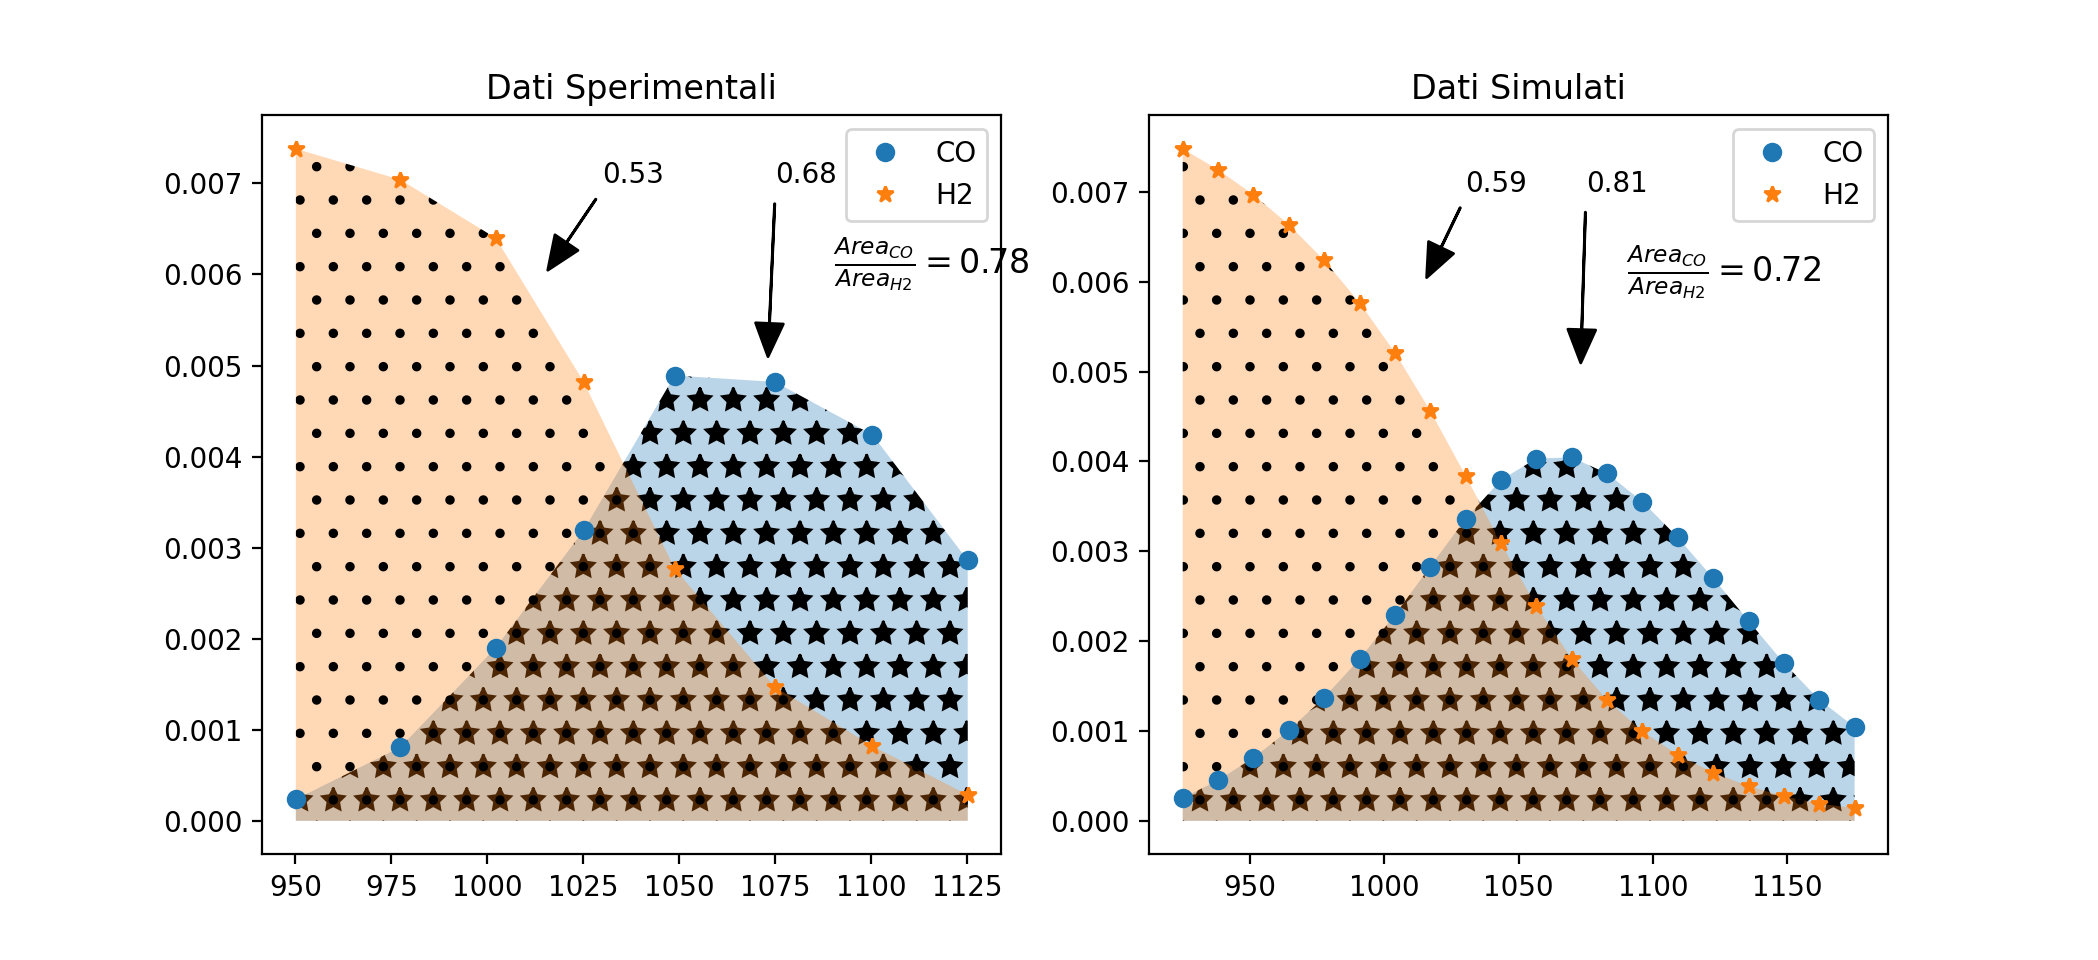

In [4]:
x1 = [950.16, 977.39, 1002.2, 1025.1, 1048.8, 1074.9, 1100.3, 1125.1]
y1 = [0.000236, 0.000808, 0.0019, 0.00319, 0.00489, 0.00482, 0.00424, 0.00286]
x2 = [950.16, 977.39, 1002.2, 1025.1, 1048.8, 1074.9, 1100.3, 1125.1]
y2 = [0.00738, 0.00704, 0.0064, 0.00482, 0.00277, 0.00147, 0.000821, 0.000285]


plt.subplot(1, 2, 1, label='Exp')

plt.plot(x1, y1, 'o', label='CO')
plt.plot(x2, y2, '*', label='H2')

plt.fill_between(x1, y1, alpha=0.30, hatch="*")
plt.fill_between(x2, y2, alpha=0.30, hatch=".")
plt.annotate('0.53', xy=(1015, 0.006), xytext=(1030, 0.007),
            arrowprops=dict(facecolor='black', shrink=0.05, width=0.1, headwidth=10))
plt.annotate('0.68', xy=(1073, 0.005), xytext=(1075, 0.007),
            arrowprops=dict(facecolor='black', shrink=0.05, width=0.1, headwidth=10))

plt.text(1090, 0.006, r'$\frac{Area_{CO}}{Area_{H2}}=0.78$', fontsize=12)

plt.title('Dati Sperimentali')

plt.legend()


x_sim_1 = [925.0, 938.1579, 951.3158, 964.4737, 977.6316, 990.7895, 1003.947, 1017.105, 1030.263, 1043.421, 1056.579, 1069.737, 1082.895, 1096.053, 1109.211, 1122.368, 1135.526, 1148.684, 1161.842, 1175.0]

y_sim_1 = [0.0002540704, 0.0004510288, 0.0007022728, 0.001008143, 0.001372472, 0.001800455, 0.002292261, 0.002830363, 0.003361922, 0.003793922, 0.004032634, 0.004045535, 0.003866851, 0.003553455, 0.00315369, 0.002701822, 0.002225003, 0.001756852, 0.001348846, 0.001044314]

x_sim_2 = [925.0, 938.1579, 951.3158, 964.4737, 977.6316, 990.7895, 1003.947, 1017.105, 1030.263, 1043.421, 1056.579, 1069.737, 1082.895, 1096.053, 1109.211, 1122.368, 1135.526, 1148.684, 1161.842, 1175.0]

y_sim_2 = [0.007480643, 0.007247854, 0.006969131, 0.006636161, 0.006239493, 0.00576829, 0.005211657, 0.004564399, 0.003840558, 0.003089722, 0.002389671, 0.001802333, 0.00134343, 0.0009960693, 0.0007346349, 0.000536682, 0.0003859445, 0.0002726114, 0.0001921665, 0.0001399616]

plt.subplot(1, 2, 2, label='Sim')

plt.plot(x_sim_1, y_sim_1, 'o', label='CO')
plt.plot(x_sim_2, y_sim_2, '*', label='H2')

plt.fill_between(x_sim_1, y_sim_1, alpha=0.30, hatch="*")
plt.fill_between(x_sim_2, y_sim_2, alpha=0.30, hatch=".")
plt.annotate('0.59', xy=(1015, 0.006), xytext=(1030, 0.007),
            arrowprops=dict(facecolor='black', shrink=0.05, width=0.1, headwidth=10))
plt.annotate('0.81', xy=(1073, 0.005), xytext=(1075, 0.007),
            arrowprops=dict(facecolor='black', shrink=0.05, width=0.1, headwidth=10))

plt.text(1090, 0.006, r'$\frac{Area_{CO}}{Area_{H2}}=0.72$', fontsize=12)
plt.title('Dati Simulati')

plt.legend()

plt.show()

In [5]:
with open('POLIMI_1212_C1C3_exp.json', 'r') as file:
    POLIMI_1212_C1C3_exp = json.load(file)


with open('POLIMI_1212_C1C3_sim.json', 'r') as file:
    POLIMI_1212_C1C3_sim = json.load(file)


with open('CRECK_2003_C1C3_DME_LTHT_exp.json', 'r') as file:
    CRECK_2003_C1C3_DME_LTHT_exp = json.load(file)


with open('CRECK_2003_C1C3_DME_LTHT_sim.json', 'r') as file:
    CRECK_2003_C1C3_DME_LTHT_sim = json.load(file)


with open('POLIMI_1212_C1C3_tot.json', 'r') as file:
    POLIMI_1212_C1C3_tot = json.load(file)


with open('CRECK_2003_C1C3_DME_LTHT_tot.json', 'r') as file:
    CRECK_2003_C1C3_DME_LTHT_tot = json.load(file)



In [6]:
labels = POLIMI_1212_C1C3_sim.keys()

means = []
means2 = []

print('Solo Sim')

for ratio in labels:
    mean1 = statistics.mean(POLIMI_1212_C1C3_sim[ratio])
    stdev1 = statistics.stdev(POLIMI_1212_C1C3_sim[ratio])
    mean2 = statistics.mean(CRECK_2003_C1C3_DME_LTHT_sim[ratio])
    stdev2 = statistics.stdev(CRECK_2003_C1C3_DME_LTHT_sim[ratio])
    
    p1 = f'POLIMI_1212: {mean1:.2f} \u00B1 {stdev1:.2f}'


    print(f'{ratio} \t --> ' + p1 + ' '*(35 - len(p1)) + f'CRECK_2003: {mean2:.2f} \u00B1 {stdev2:.2f}')
    
    

Solo Sim
CO_x/H2_x 	 --> POLIMI_1212: 1.64 ± 2.85           CRECK_2003: 1.93 ± 3.33
CO_x/H2O_x 	 --> POLIMI_1212: 0.23 ± 0.12           CRECK_2003: 0.20 ± 0.12
CO_x/CH2O_x 	 --> POLIMI_1212: 22.85 ± 12.33         CRECK_2003: 19.76 ± 8.36
CO_x/C2H4_x 	 --> POLIMI_1212: 33.42 ± 30.84         CRECK_2003: 39.03 ± 23.41
CO_x/CH4_x 	 --> POLIMI_1212: 0.59 ± 0.36           CRECK_2003: 0.71 ± 0.37
H2_x/H2O_x 	 --> POLIMI_1212: 0.27 ± 0.13           CRECK_2003: 0.22 ± 0.09
H2_x/CH2O_x 	 --> POLIMI_1212: 57.00 ± 57.32         CRECK_2003: 34.53 ± 27.72
H2_x/C2H4_x 	 --> POLIMI_1212: 51.51 ± 42.00         CRECK_2003: 53.50 ± 35.08
H2_x/CH4_x 	 --> POLIMI_1212: 1.39 ± 1.17           CRECK_2003: 1.23 ± 0.94
H2O_x/CH2O_x 	 --> POLIMI_1212: 146.46 ± 121.00       CRECK_2003: 136.06 ± 93.38
H2O_x/C2H4_x 	 --> POLIMI_1212: 196.40 ± 191.57       CRECK_2003: 338.35 ± 535.60
H2O_x/CH4_x 	 --> POLIMI_1212: 3.68 ± 3.34           CRECK_2003: 4.55 ± 4.12
CH2O_x/C2H4_x 	 --> POLIMI_1212: 1.62 ± 1.50           CR

In [7]:
labels = POLIMI_1212_C1C3_tot.keys()

means = []
means2 = []


print('Var % Exp-Sim')

for ratio in labels:
    mean1 = statistics.mean(POLIMI_1212_C1C3_tot[ratio])
    stdev1 = statistics.stdev(POLIMI_1212_C1C3_tot[ratio])
    mean2 = statistics.mean(CRECK_2003_C1C3_DME_LTHT_tot[ratio])
    stdev2 = statistics.stdev(CRECK_2003_C1C3_DME_LTHT_tot[ratio])
    
    p1 = f'POLIMI_1212: {mean1:.2f} \u00B1 {stdev1:.2f}'


    print(f'{ratio} \t --> ' + p1 + ' '*(35 - len(p1)) + f'CRECK_2003: {mean2:.2f} \u00B1 {stdev2:.2f}')
    
    

Var % Exp-Sim
CO_x/H2_x 	 --> POLIMI_1212: 64.55 ± 57.03         CRECK_2003: 30.89 ± 35.67
CO_x/H2O_x 	 --> POLIMI_1212: 6.02 ± 20.23          CRECK_2003: 0.92 ± 23.40
CO_x/CH2O_x 	 --> POLIMI_1212: -3.71 ± 38.88         CRECK_2003: -1.28 ± 50.07
CO_x/C2H4_x 	 --> POLIMI_1212: 21.79 ± 68.91         CRECK_2003: 34.15 ± 81.25
CO_x/CH4_x 	 --> POLIMI_1212: 35.98 ± 67.73         CRECK_2003: 13.66 ± 34.09
H2_x/H2O_x 	 --> POLIMI_1212: -24.60 ± 30.33        CRECK_2003: -16.45 ± 28.99
H2_x/CH2O_x 	 --> POLIMI_1212: -18.21 ± 25.43        CRECK_2003: -11.35 ± 19.06
H2_x/C2H4_x 	 --> POLIMI_1212: -14.71 ± 22.05        CRECK_2003: 1.42 ± 20.17
H2_x/CH4_x 	 --> POLIMI_1212: 13.35 ± 49.04         CRECK_2003: 0.38 ± 16.97
H2O_x/CH2O_x 	 --> POLIMI_1212: -1.79 ± 5.49          CRECK_2003: -0.70 ± 2.27
H2O_x/C2H4_x 	 --> POLIMI_1212: 80417.34 ± 341200.54  CRECK_2003: 99118.02 ± 420509.35
H2O_x/CH4_x 	 --> POLIMI_1212: 262.32 ± 1039.87      CRECK_2003: 252.50 ± 1056.18
CH2O_x/C2H4_x 	 --> POLIMI_1212: 2